# Corn Leaf & Stem Instance Segmentation with YOLOv11

Instance segmentation of **maize leaves and stems** in field images using Ultralytics **YOLOv11-seg**, with:

1. A **model-size experiment** (`yolo11n-seg` vs `yolo11s-seg`) with a hypothesis stated *before* training.
2. A **manual error audit** of validation predictions (false positives vs. false negatives, missing labels vs. model errors).

**Author:** Pedro Damián Reyes Alvarado — B.Eng. Artificial Intelligence, Universidad Panamericana (Aguascalientes, Mexico)

> Runs on Google Colab with a free **T4 GPU** (*Runtime → Change runtime type → T4 GPU*). See the repository README for the full write-up of results and limitations.

## 1. Setup

In [8]:
!pip install -q ultralytics roboflow

import ultralytics
ultralytics.checks()

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.6/112.6 GB disk)


## 2. Sanity check: a pretrained model out of the box

Before training, run a COCO-pretrained `yolo11n-seg` on a sample image to inspect what the model returns:
class IDs (`boxes.cls`), confidences (`boxes.conf`) and masks (`masks.data`).

`conf` is the minimum confidence kept and `iou` is the NMS overlap threshold. Lowering `conf` raises recall
but adds low-confidence and duplicate detections — the same precision/recall trade-off analysed later.


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 13.2ms
Speed: 2.0ms preprocess, 13.2ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)


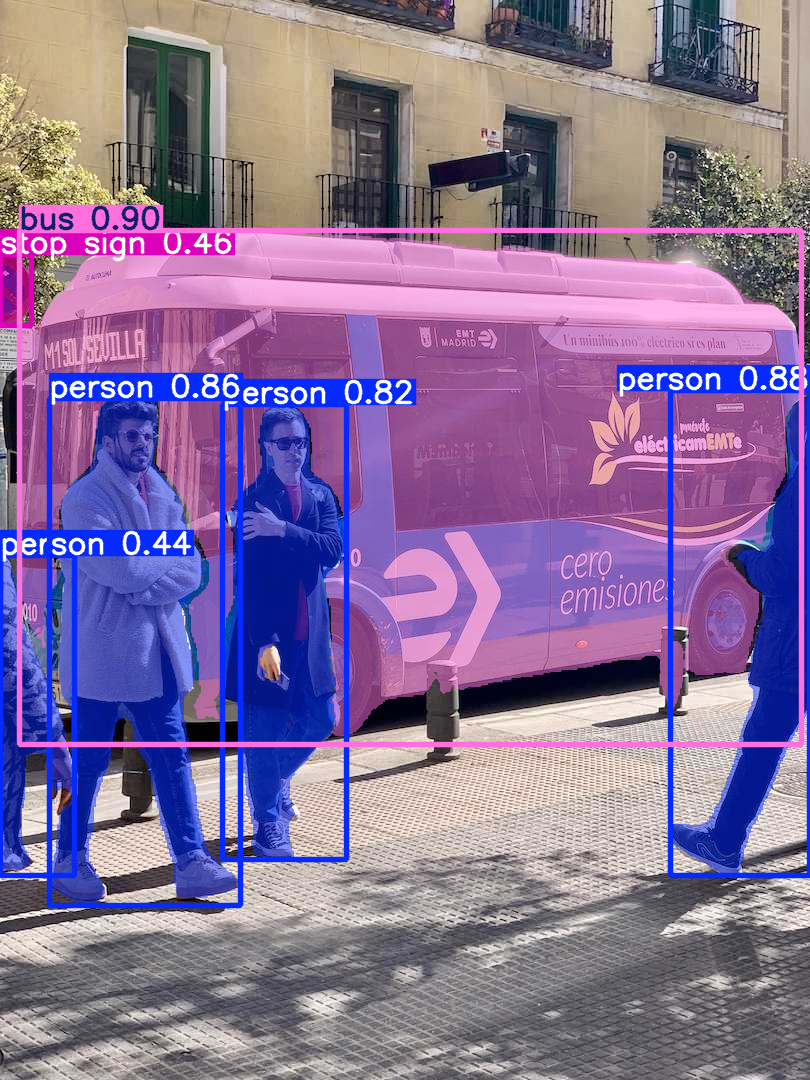

Mask tensor shape (objects, H, W): (6, 640, 480)
            bus: 0.90
         person: 0.88
         person: 0.86
         person: 0.82
      stop sign: 0.46
         person: 0.44


In [9]:
from ultralytics import YOLO

pretrained = YOLO("yolo11n-seg.pt")

SAMPLE = "https://ultralytics.com/images/bus.jpg"   # or upload your own image and use its /content/... path
result = pretrained(SAMPLE, conf=0.25, iou=0.7)[0]  # default thresholds
result.show()

print("Mask tensor shape (objects, H, W):", tuple(result.masks.data.shape))
for cls_id, conf in zip(result.boxes.cls, result.boxes.conf):
    print(f"{result.names[int(cls_id)]:>15}: {float(conf):.2f}")

## 3. Dataset

[Corn – Roboflow Universe](https://universe.roboflow.com/aurora-va3tw/corn-lpwdh) (CC BY 4.0), version 2, exported in YOLOv11 format.
Two classes: `leaf` (0) and `stem` (1). Labels are polygons with coordinates normalised to [0, 1].

**API key:** never hard-code it. Store it in Colab's **Secrets** panel (🔑 icon, left sidebar) as `ROBOFLOW_API_KEY`;
the cell falls back to a hidden prompt if the secret is missing.

In [10]:
from roboflow import Roboflow

try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    from getpass import getpass
    API_KEY = getpass("Roboflow API key: ")

rf = Roboflow(api_key=API_KEY)
dataset = rf.workspace("aurora-va3tw").project("corn-lpwdh").version(2).download("yolov11")

DATA_YAML = f"{dataset.location}/data.yaml"
print(open(DATA_YAML).read())

Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['leaf', 'stem']

roboflow:
  workspace: aurora-va3tw
  project: corn-lpwdh
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/aurora-va3tw/corn-lpwdh/dataset/2


In [11]:
from pathlib import Path

for split in ["train", "valid", "test"]:
    n = len(list(Path(dataset.location, split, "images").glob("*")))
    print(f"{split:>5}: {n} images")

train: 471 images
valid: 134 images
 test: 67 images


## 4. Experiment: does a bigger model help?

**Hypothesis (stated before training):** the dataset — not model capacity — limits performance, so `yolo11s-seg`
(~3× the parameters of `yolo11n-seg`) will **not** improve mask mAP50 meaningfully.

**Decision rule (fixed in advance):** a change smaller than **±0.02** mask mAP50 counts as "no change".

Both models: COCO-pretrained (transfer learning), 50 epochs, `imgsz=640`, Ultralytics defaults
(optimizer auto-selected — AdamW for this run length — with warm-up and learning-rate decay). Only the model changes.

In [12]:
EPOCHS, IMGSZ, SEED = 50, 640, 0

RUNS = {}  # model name -> folder where Ultralytics saved the run

model_n = YOLO("yolo11n-seg.pt")
model_n.train(data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, seed=SEED, name="yolo11n", exist_ok=True)
RUNS["yolo11n"] = model_n.trainer.save_dir   # read the real path instead of guessing it
print("Saved to:", RUNS["yolo11n"])

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/corn-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n, nbs=64, nms=None, opset=None, optimize=False, optimi

In [13]:
model_s = YOLO("yolo11s-seg.pt")
model_s.train(data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, seed=SEED, name="yolo11s", exist_ok=True)
RUNS["yolo11s"] = model_s.trainer.save_dir
print("Saved to:", RUNS["yolo11s"])

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/corn-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s, nbs=64, nms=None, opset=None, optimize=False, optimi

## 5. Evaluation (validation set, per class)

If the Colab session restarted after training, `RUNS` is empty: re-run the training cells, or set it by hand to the folders
found with `!find /content -name best.pt` (e.g. `RUNS = {"yolo11n": "...", "yolo11s": "..."}`).

Each run's `best.pt` is evaluated on the validation split. **Box** and **Mask** metrics are reported for `leaf` and `stem`.

In [14]:
import pandas as pd

rows = []
for name, run_dir in RUNS.items():
    best = YOLO(f"{run_dir}/weights/best.pt")
    m = best.val(data=DATA_YAML, split="val", plots=False, verbose=False)
    for i, cls in m.names.items():
        rows.append({"model": name, "class": cls,
                     "mask_mAP50": round(float(m.seg.ap50[i]), 3),
                     "mask_mAP50-95": round(float(m.seg.maps[i]), 3)})
    rows.append({"model": name, "class": "all",
                 "mask_mAP50": round(float(m.seg.map50), 3),
                 "mask_mAP50-95": round(float(m.seg.map), 3)})

table = pd.DataFrame(rows).pivot(index="class", columns="model", values="mask_mAP50")
table["diff (s - n)"] = (table["yolo11s"] - table["yolo11n"]).round(3)
table["no change (|diff| < 0.02)"] = table["diff (s - n)"].abs() < 0.02
table

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,710 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1933.4±747.6 MB/s, size: 62.4 KB)
val: Scanning /content/corn-2/valid/labels.cache... 134 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 134/134 37.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.3it/s 2.7s
                   all        134       1018      0.496      0.505      0.465      0.276      0.521       0.52      0.496      0.288
Speed: 1.3ms preprocess, 8.0ms inference, 0.0ms loss, 2.8ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,590 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2394.0±

model,yolo11n,yolo11s,diff (s - n),no change (|diff| < 0.02)
class,,,,
all,0.496,0.493,-0.003,True
leaf,0.535,0.523,-0.012,True
stem,0.457,0.463,0.006,True


### Training curves

`train/*` losses falling with `val/*` losses also falling (no divergence) means no overfitting; a flat mAP in the
last epochs alongside a learning rate decayed to ~0 signals a plateau.

yolo11n


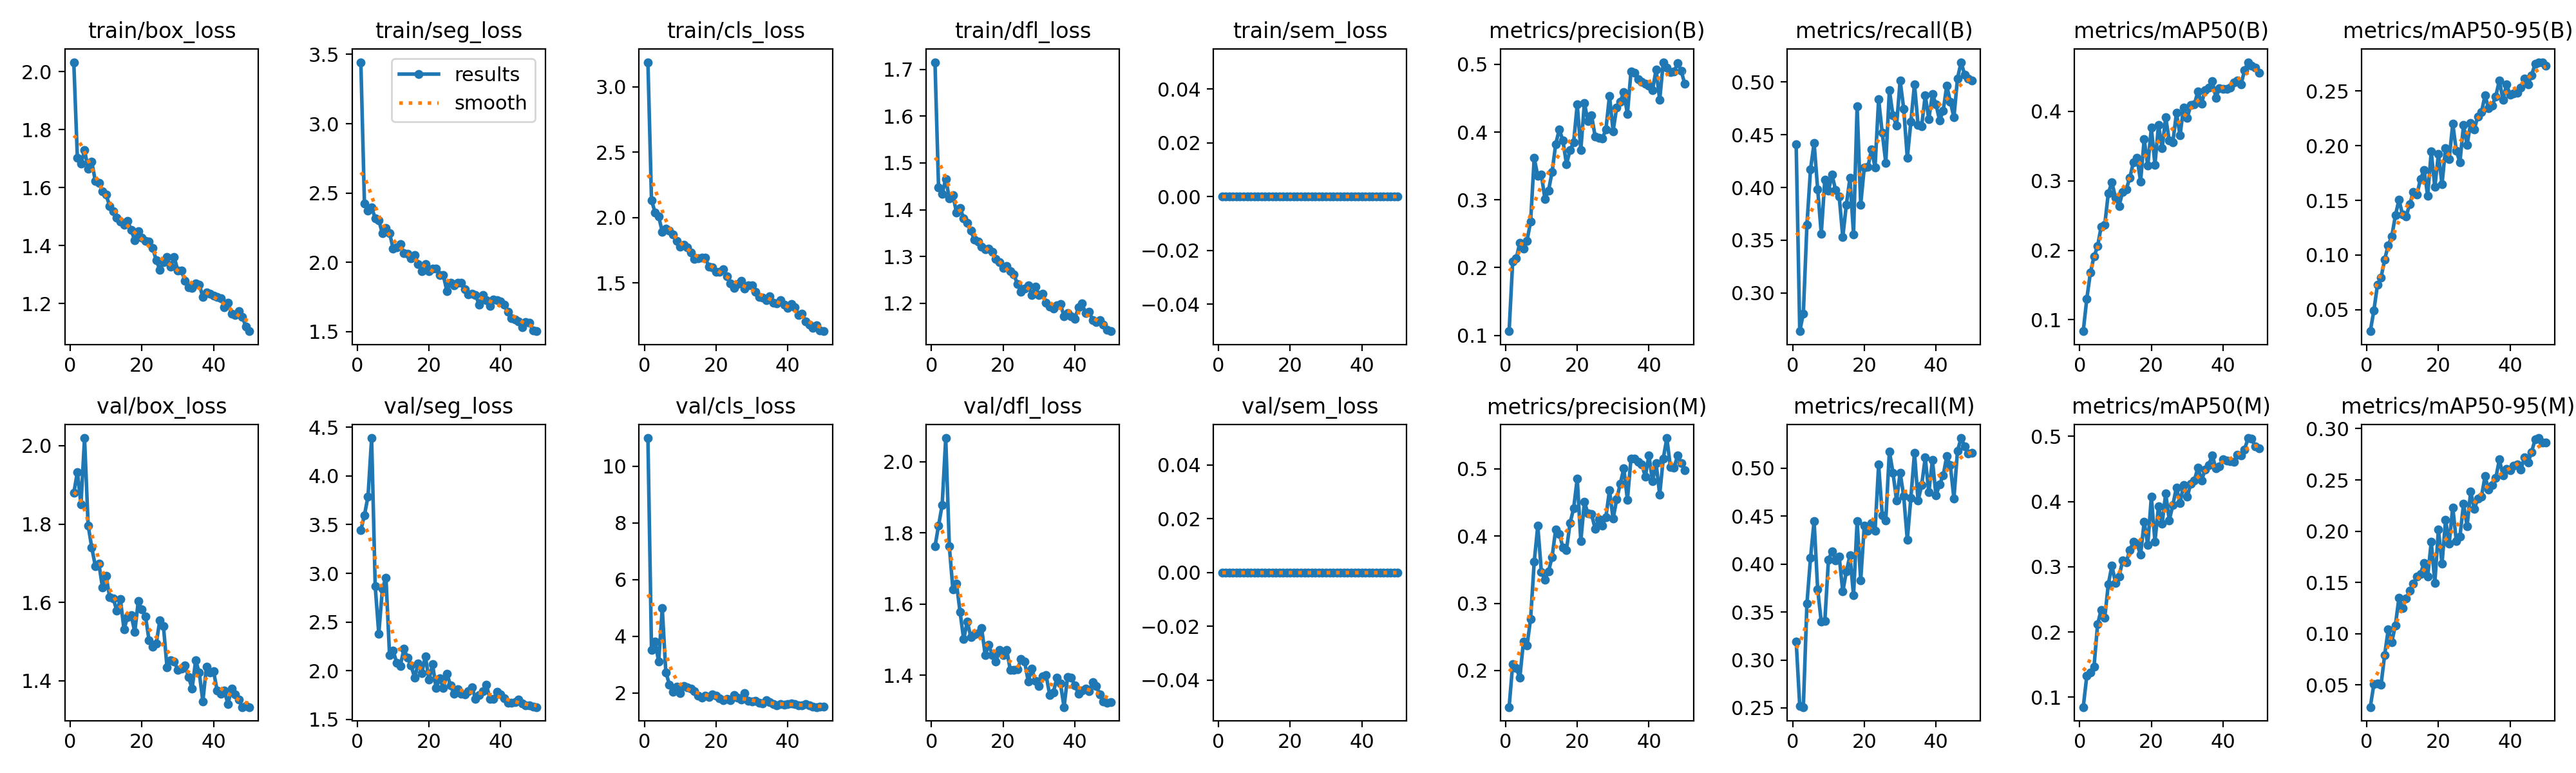

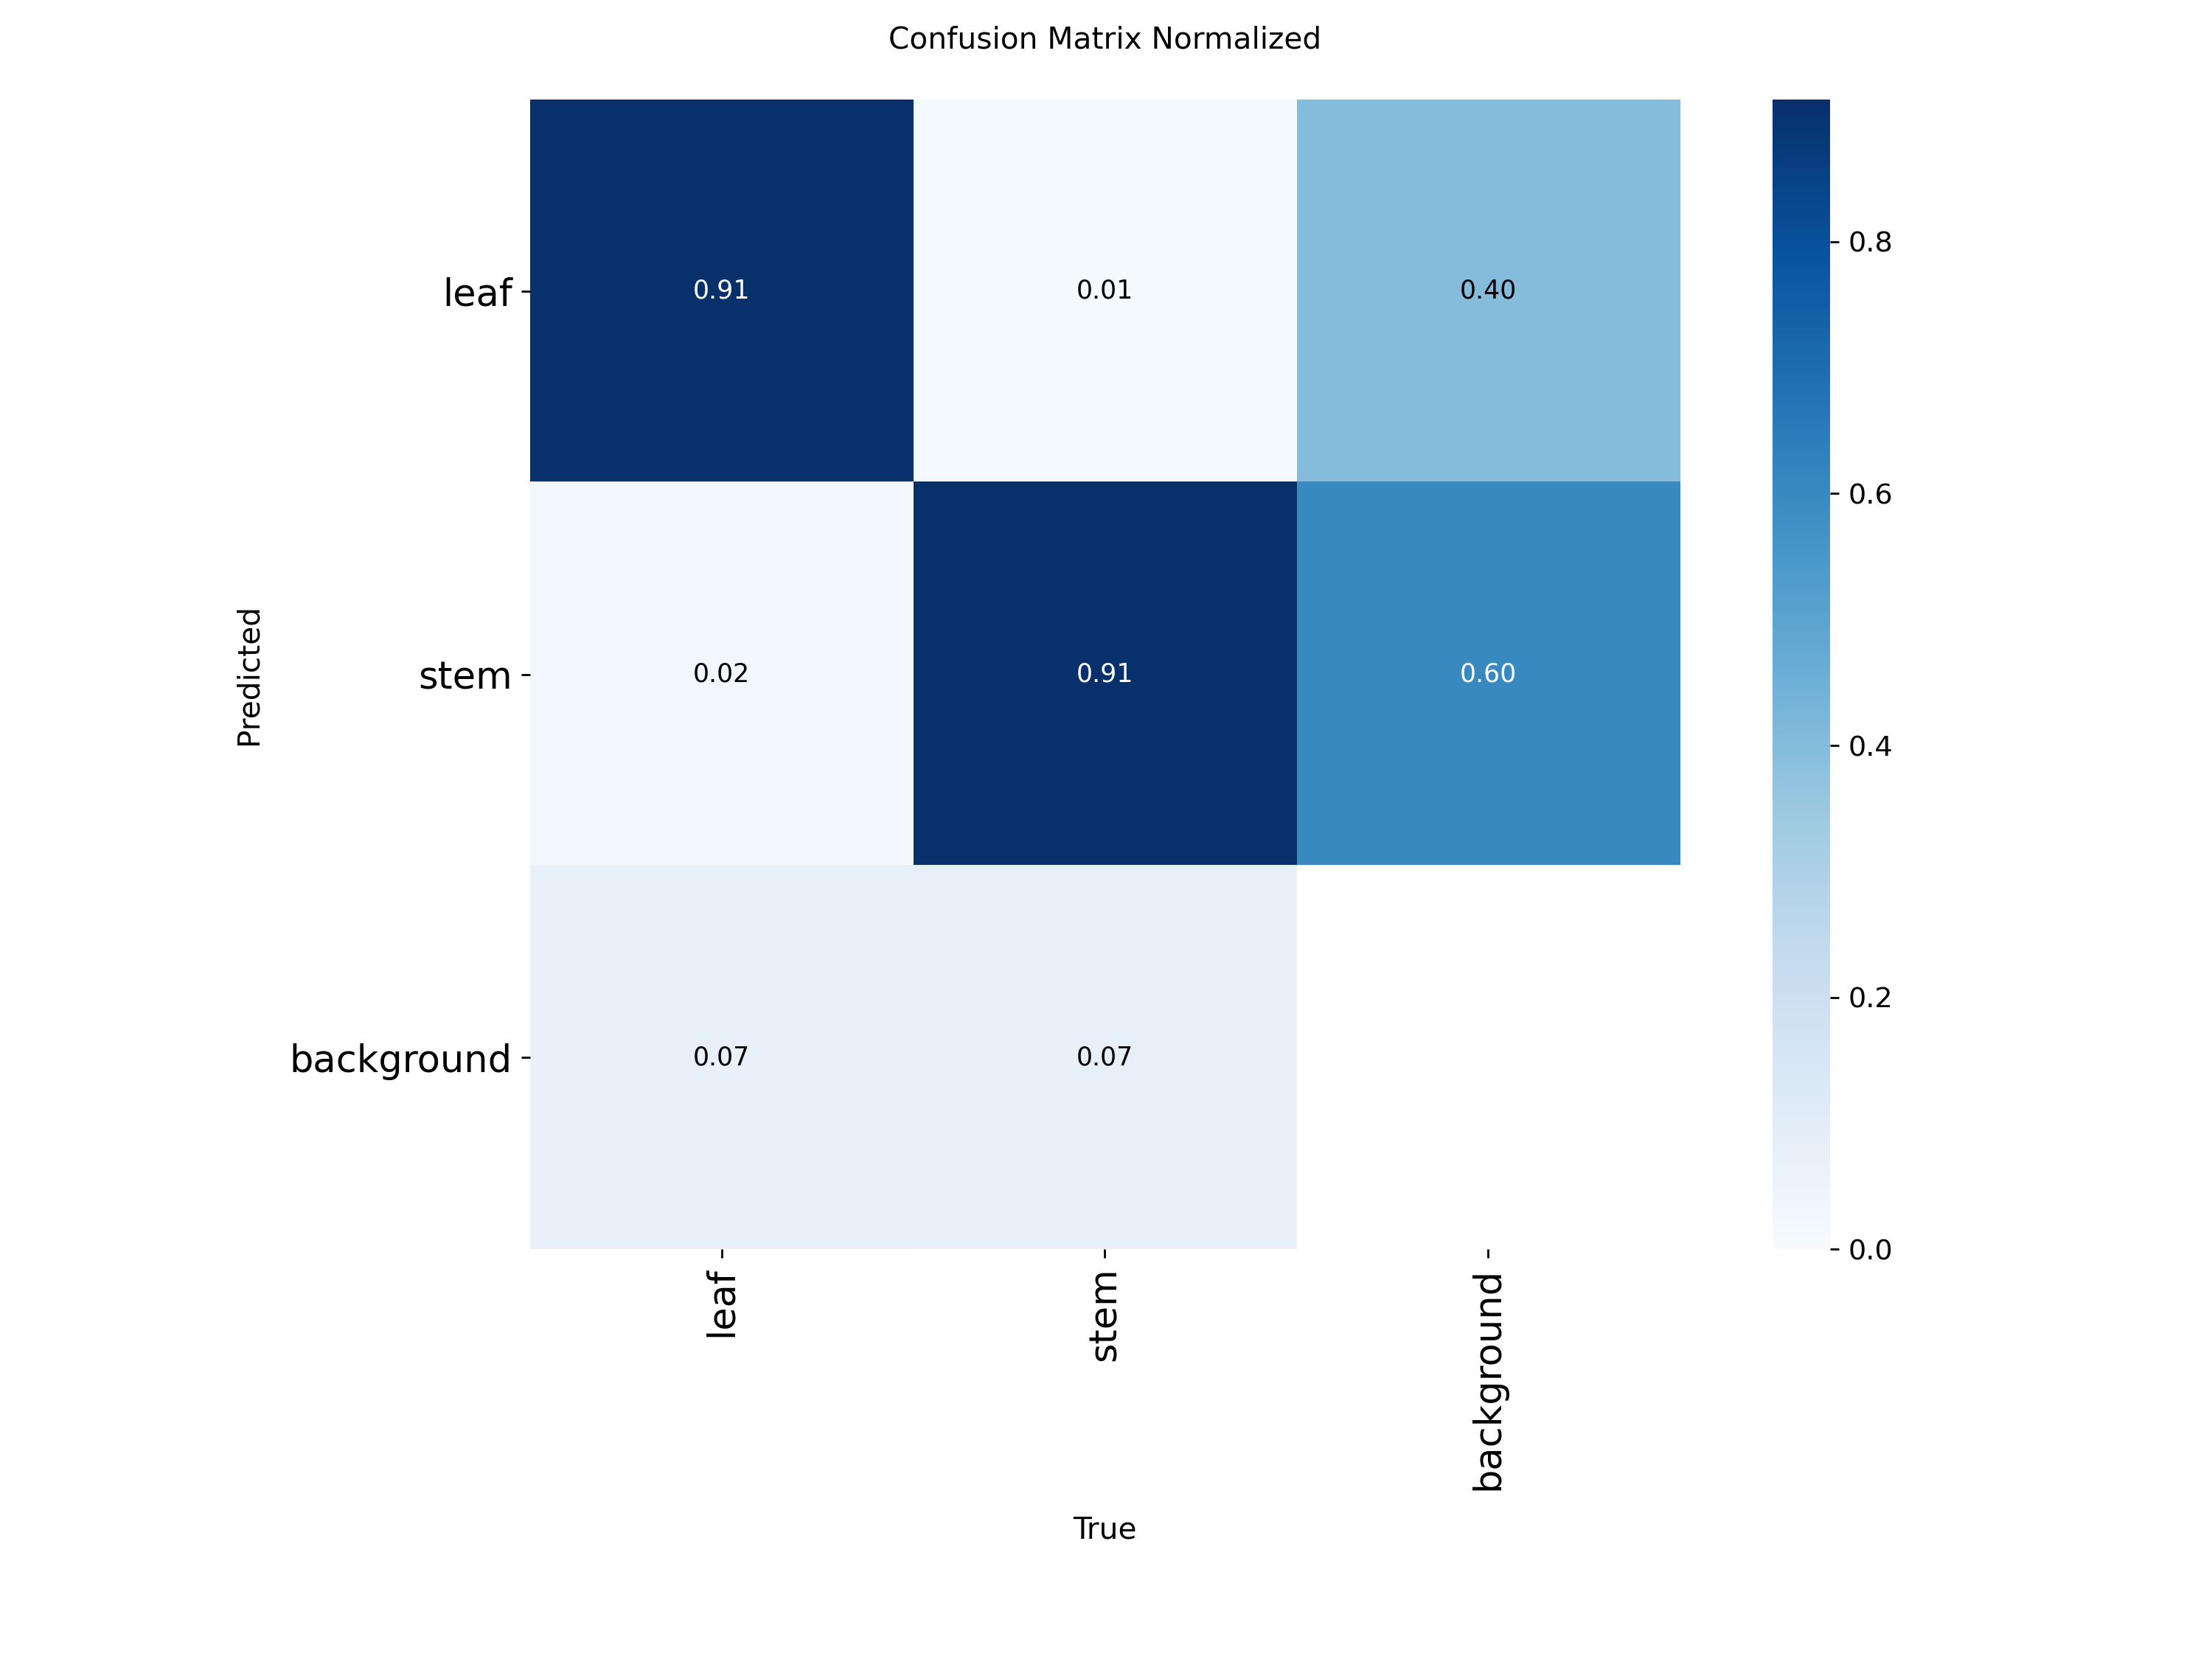

yolo11s


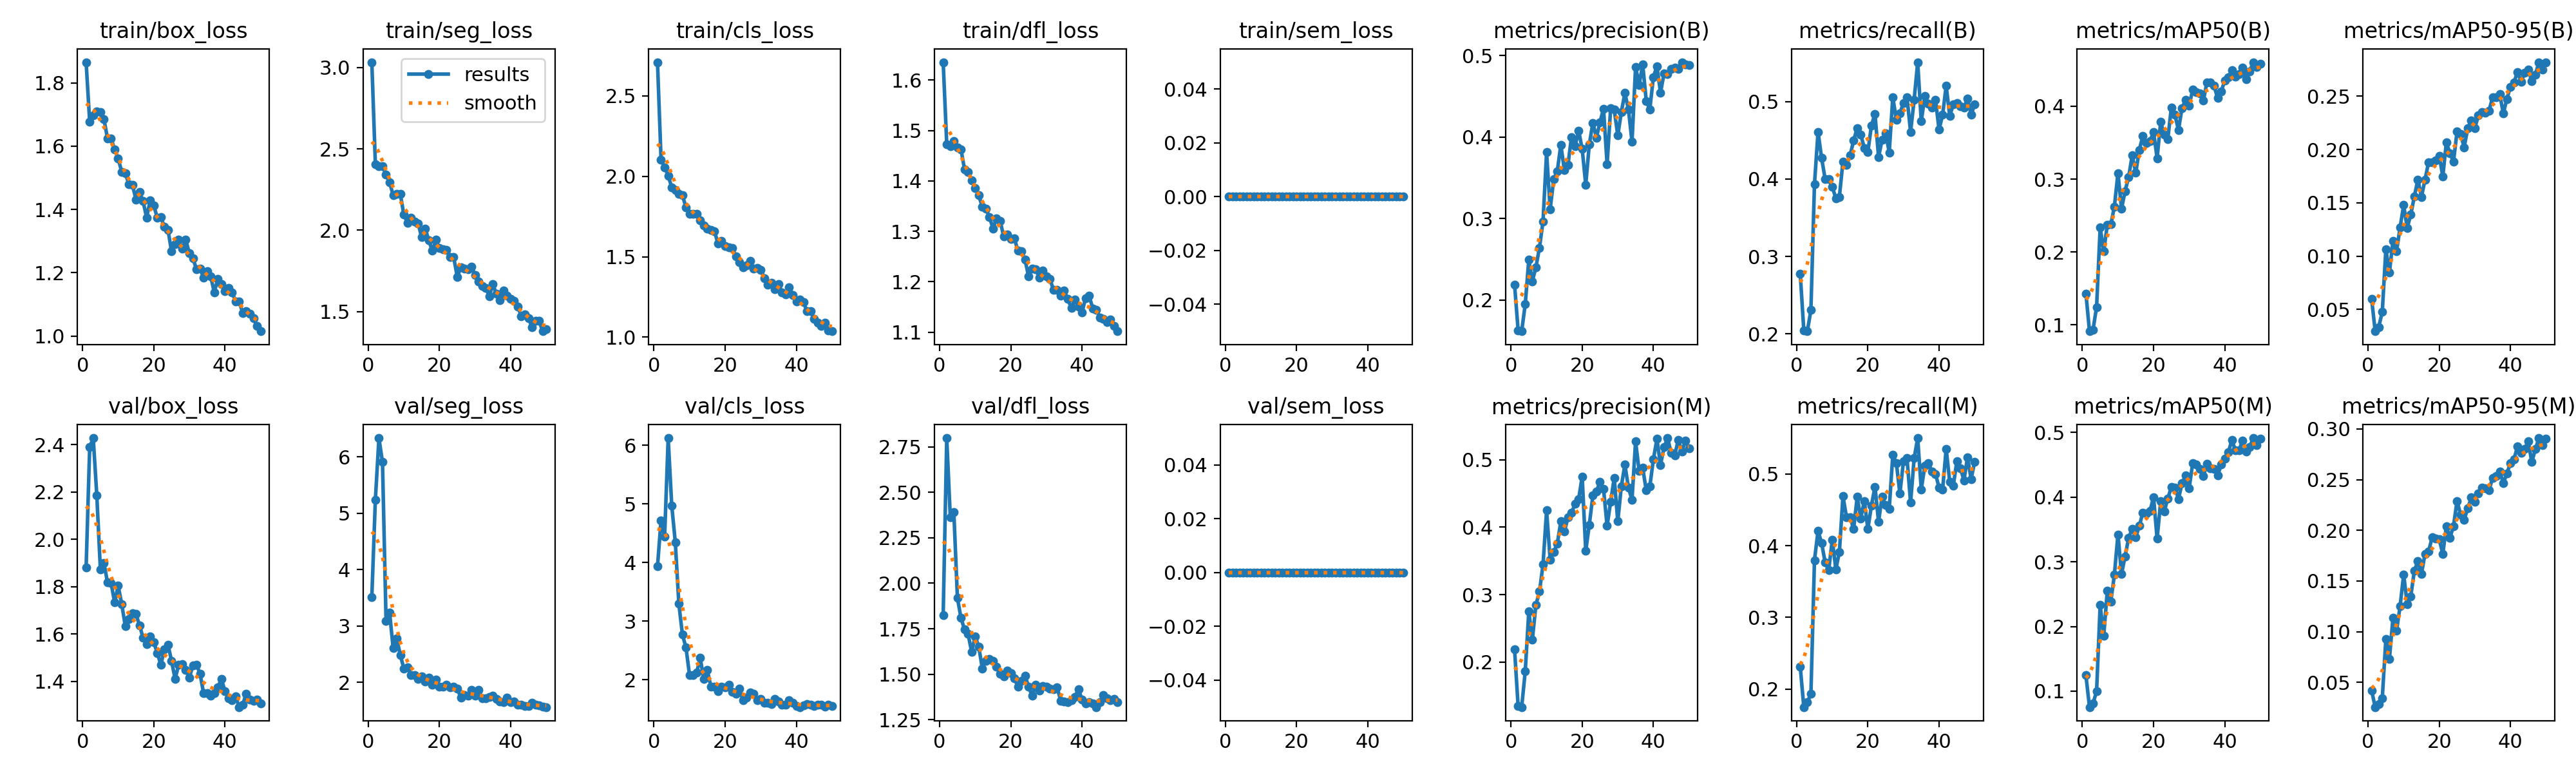

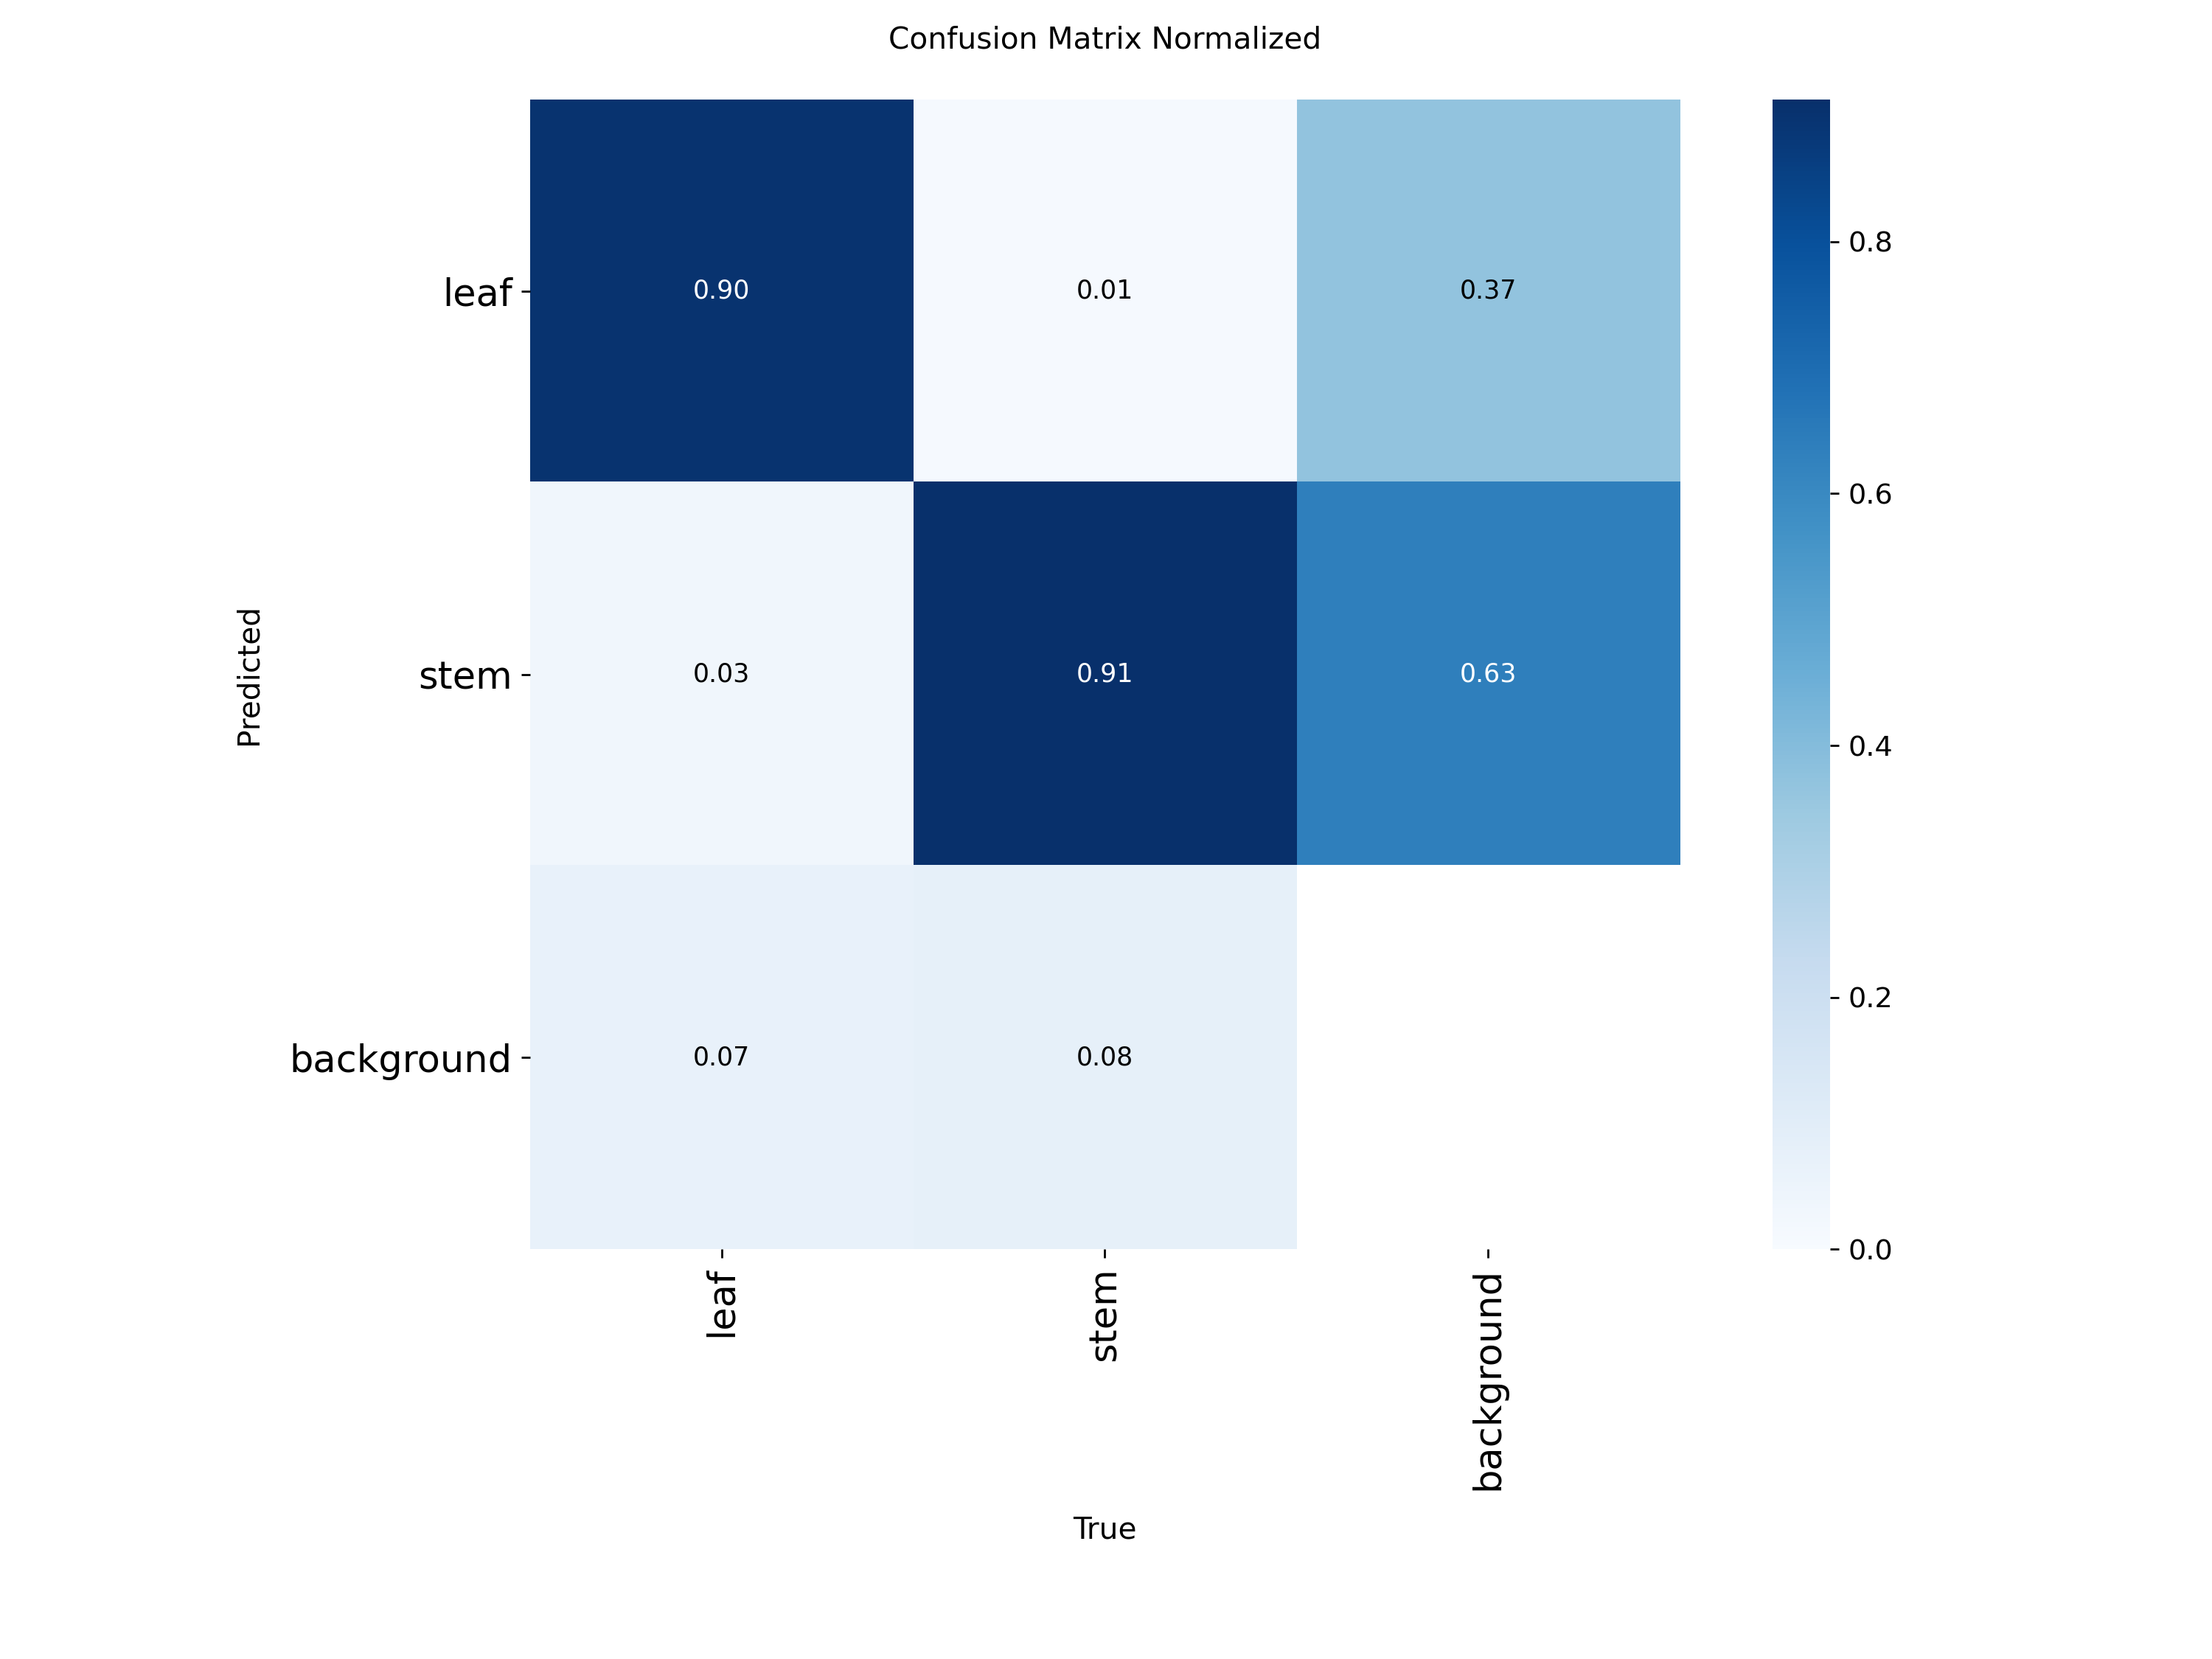

In [15]:
from IPython.display import Image, display

for name, run_dir in RUNS.items():
    print(name)
    display(Image(f"{run_dir}/results.png", width=900))
    display(Image(f"{run_dir}/confusion_matrix_normalized.png", width=500))

## 6. Qualitative check: labels vs. predictions

Compare ground truth (`*_labels.jpg`) with predictions (`*_pred.jpg`) side by side. This is the starting point of the
manual audit: every prediction without a matching label is a **false positive** (a missing label, a duplicate,
a wrong class, or unclear), and every label without a prediction is a **false negative**.

labels


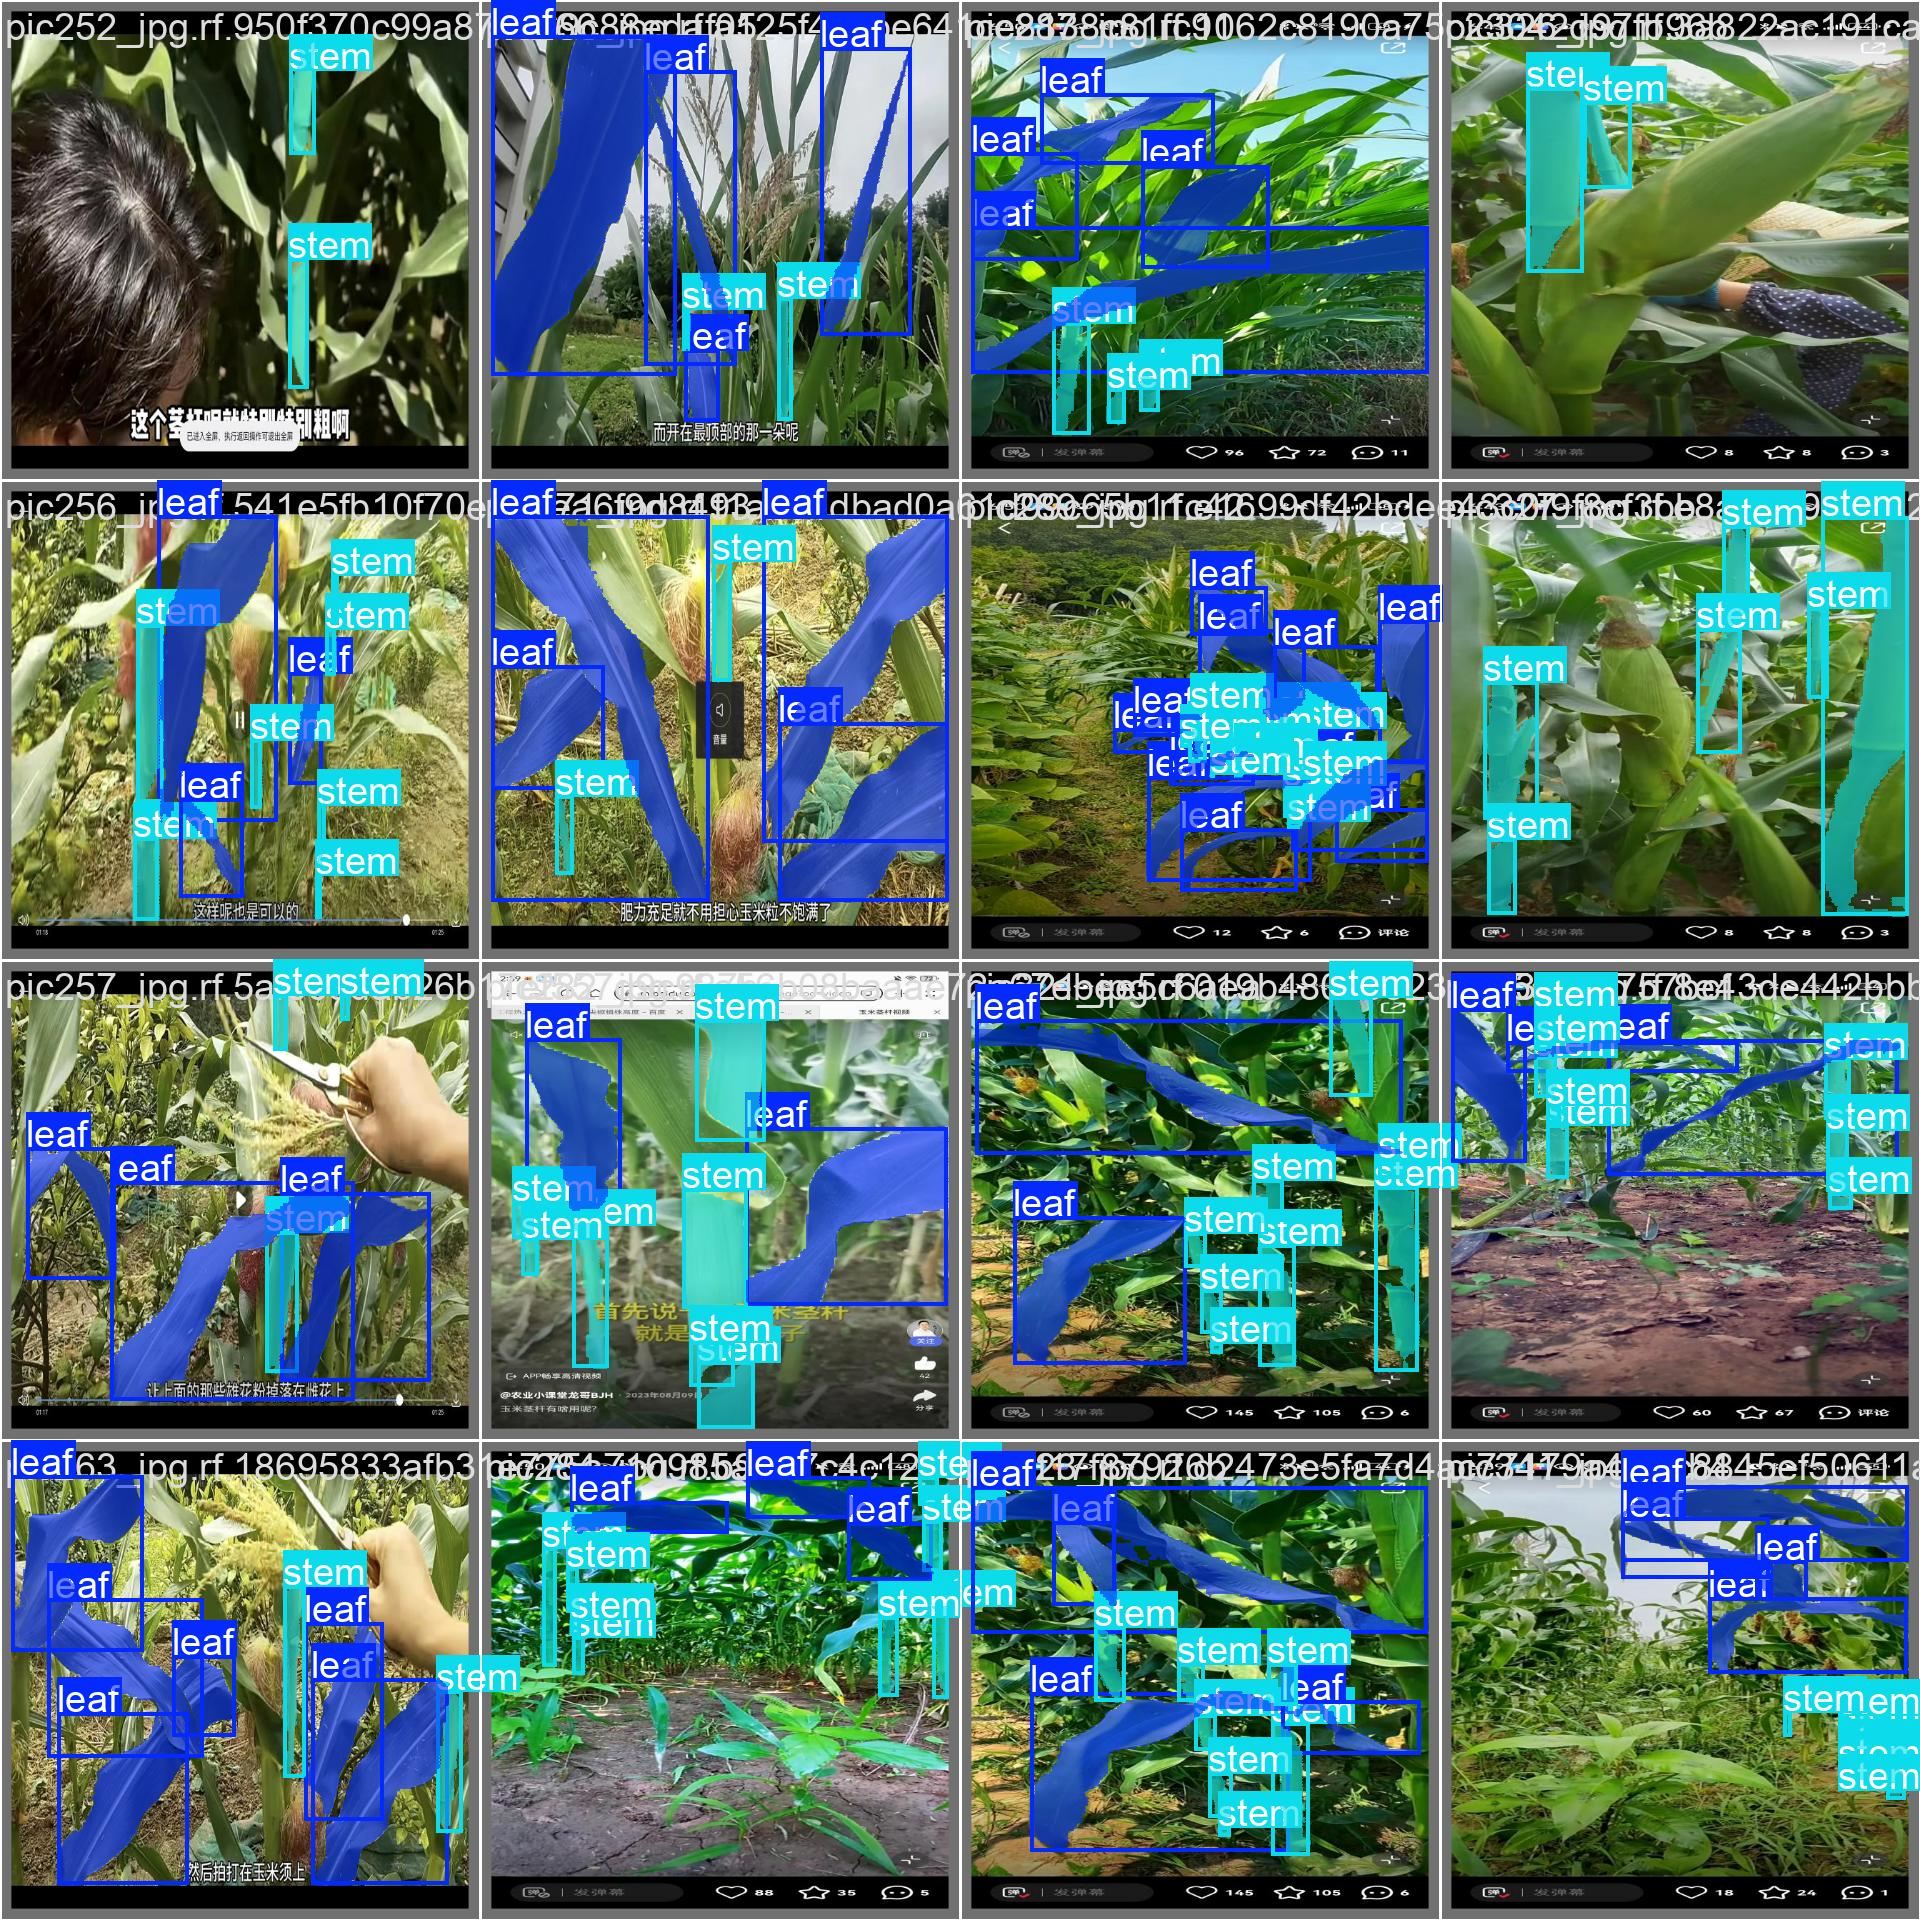

pred


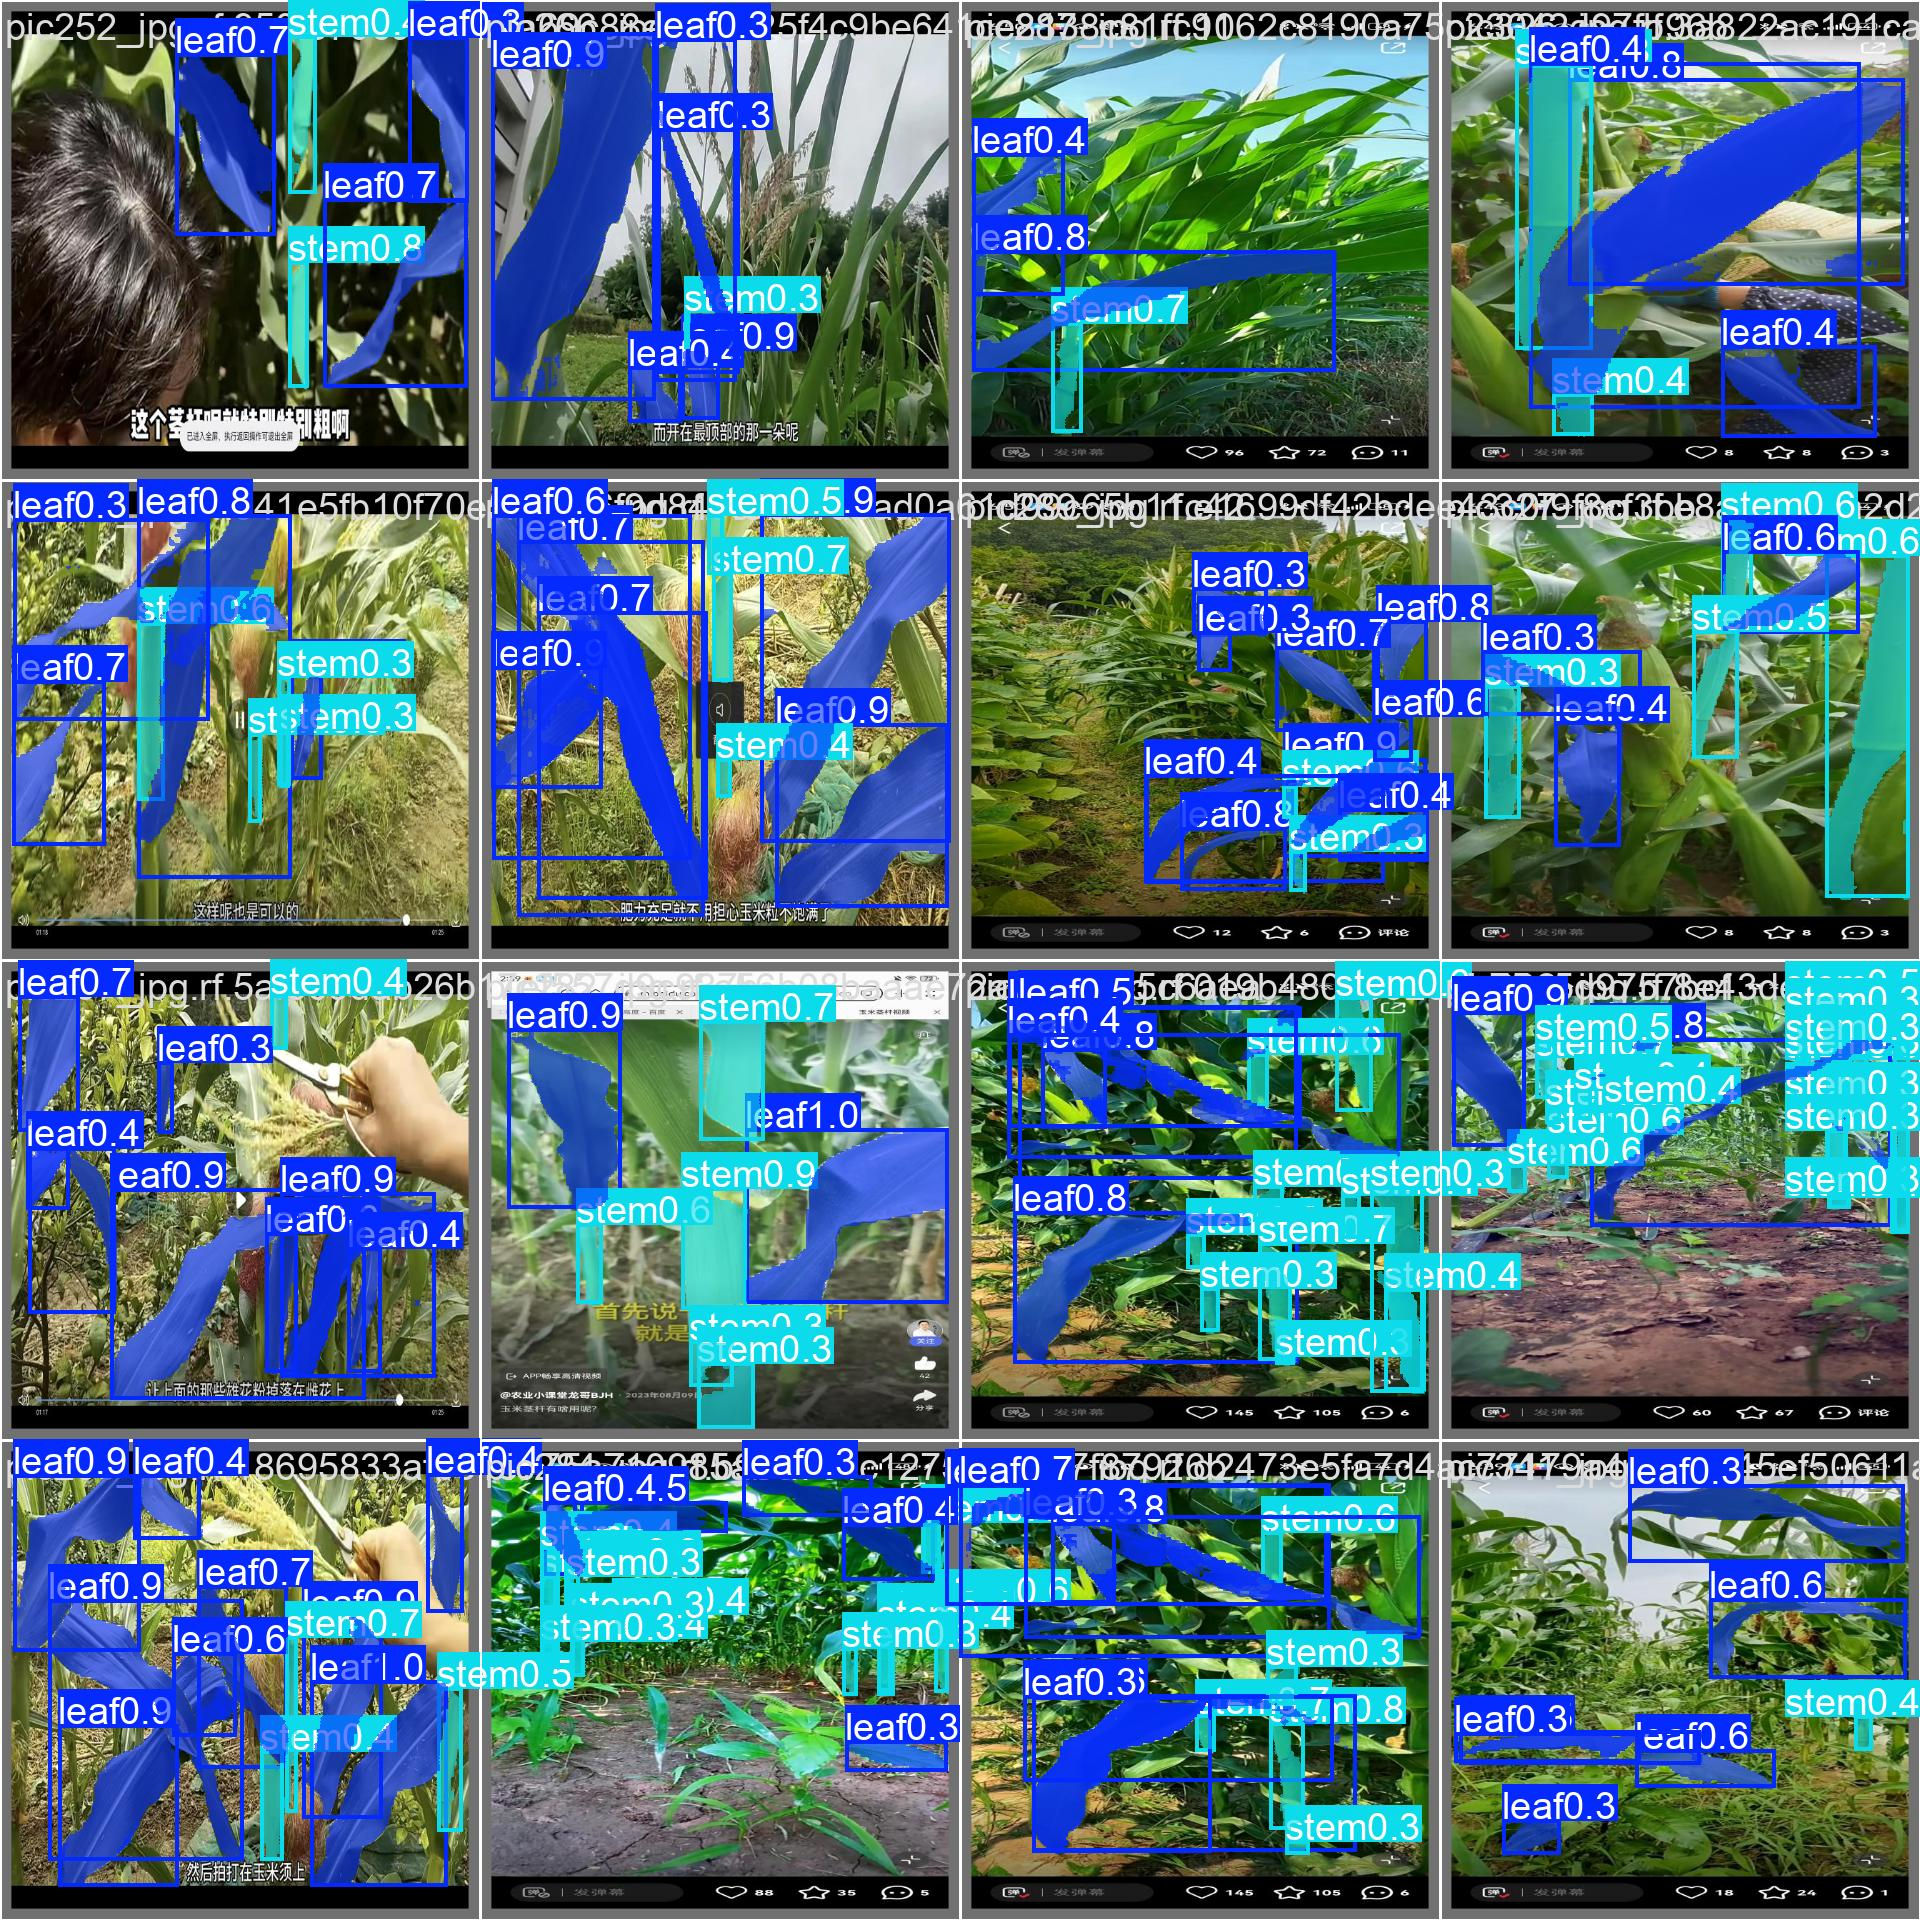

In [16]:
run = RUNS["yolo11n"]
for kind in ["labels", "pred"]:
    print(kind)
    display(Image(f"{run}/val_batch0_{kind}.jpg", width=900))

## 7. Findings (summary)

| Model | Mask mAP50 (all) | Leaf | Stem |
|---|---|---|---|
| yolo11n-seg | 0.496 | 0.535 | 0.457 |
| yolo11s-seg | 0.493 | 0.523 | 0.463 |

- **Hypothesis confirmed:** all differences are within ±0.02 — a ~3× larger model brings no gain, pointing to a data ceiling.
- **Manual audit** (16 validation images): of 38 false positives, 21% were visible objects **missing from the labels**,
  37% were **model errors** (mostly duplicate masks, plus wrong classes such as an ear of corn predicted as a leaf) and 42% were unclear.
  Of 28 false negatives, **23 were stems** — thin objects are the model's main weakness.
- Metrics therefore **underestimate** true performance (missing labels count as false positives), but label noise does not explain everything.

*Numbers above are from the author's original runs; re-running may differ slightly. See the README for limitations.*

## 8. Save results

Download the run folders (metrics, curves, confusion matrices, example predictions). Weights are excluded from the repository.

In [17]:
import shutil, subprocess

subprocess.run(["zip", "-qr", "results.zip", *map(str, RUNS.values()), "-x", "*.pt"], check=True)

from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>